In [1]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="llama3.2:latest")
print('Model is ready')

Model is ready


In [ ]:
# STEP 1: Define your state
from typing import TypedDict
from langchain_core.messages import AnyMessage
from langgraph.graph.message import Annotated, add_messages

class ChatState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

print('State is defined')

State is defined


In [3]:
def assistant_node(state: ChatState) -> dict:
    """One graph noce: call the LLM using current messages"""
    response = model.invoke(state['messages'])
    return { "messages": state["messages"] + [response]}
print('Nodes are defined')

Nodes are defined


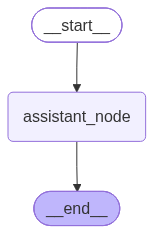

In [10]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import HumanMessage

graph_builder = StateGraph(ChatState)

# Node registration
graph_builder.add_node("assistant_node", assistant_node)

# Add edges to nodes
graph_builder.add_edge(START, "assistant_node")
graph_builder.add_edge("assistant_node", END)
memory = MemorySaver()
graph = graph_builder.compile(checkpointer=memory)
graph

In [11]:
def chat(user_input, session_id):

    config = {
        "configurable": {
            "thread_id": session_id
        }
    }

    response = graph.invoke(
        {
            "messages": [
                HumanMessage(content=user_input)
            ]
        },
        config=config
    )

    return response["messages"][-1].content

In [ ]:
print(chat("My name is Bapurao","userA"))

Namaskar Bapurao! (Namaste Bapurao!) It's nice to meet you. How can I assist you today?


In [ ]:
print(chat("What is my name?","userA"))

Your name is Bapurao.


In [14]:
print(chat("My name is John", "userB"))

Nice to meet you, John! Is there something I can help you with, or would you like to chat for a bit?


In [15]:
print(chat("What is my name?","userB"))

You told me your name is John earlier!


In [16]:
print(chat("What is my name?","userA"))

Your name is Bapurao.
